In [1]:
"""import uproot
import polars as pl
import numpy as np
tree = uproot.open("Liquid_scin/DAQ/25C25_Cf_R6094_820V/UNFILTERED/Data_CH0@DT5730SB_27616_25C25_Cf_R6094_820V.root")["Data"]
df = tree.arrays(library="np")
data = pl.DataFrame(df)
samples = np.concatenate(data['Samples']).reshape(len(data['Samples']),-1)
samples = pl.Series("Samples", samples)
data = data.with_columns(samples)
"""

'import uproot\nimport polars as pl\nimport numpy as np\ntree = uproot.open("Liquid_scin/DAQ/25C25_Cf_R6094_820V/UNFILTERED/Data_CH0@DT5730SB_27616_25C25_Cf_R6094_820V.root")["Data"]\ndf = tree.arrays(library="np")\ndata = pl.DataFrame(df)\nsamples = np.concatenate(data[\'Samples\']).reshape(len(data[\'Samples\']),-1)\nsamples = pl.Series("Samples", samples)\ndata = data.with_columns(samples)\n'

In [1]:
import polars as pl

In [2]:
data = pl.read_parquet(
    "C:/proga/neutron_vs_gamma/datasets/25c25.parquet"
)

In [3]:
data.shape

(509697, 8)

In [4]:
data.head(3)

Channel,Timestamp,Board,Energy,EnergyShort,Flags,Probe,Samples
u16,u64,u16,u16,u16,u32,i32,"array[i16, 144]"
0,44313205,0,565,521,16384,1,"[13562, 13566, … 13547]"
0,158492083,0,828,773,16384,1,"[13556, 13554, … 13515]"
0,172405635,0,361,328,16384,1,"[13560, 13543, … 13558]"


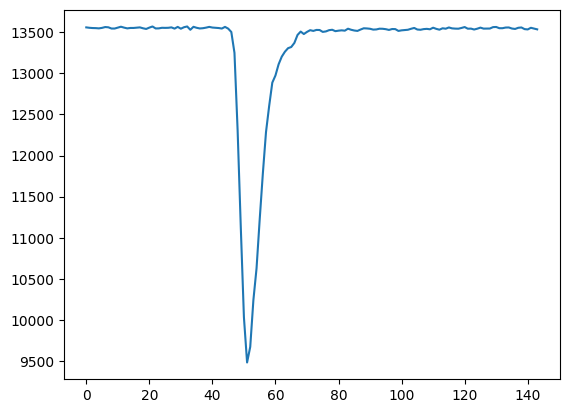

In [5]:
import matplotlib.pyplot as plt 
plt.plot(data['Samples'][100])

In [6]:
data = data.with_columns(
    pl.col("Samples").cast(pl.List)
)

In [8]:
processed_data = (
    data
    .with_columns(
        pulse = pl.col("Samples").list.eval(
            pl.element().slice(0, 30).mean() - pl.element()
        )
    )
    .with_columns(
        amplitude = pl.col("pulse").list.max()
    )
    .with_columns(
        psd = (pl.col("Energy") -  pl.col("EnergyShort"))/ pl.col("Energy")
    )
    .with_columns(
        norm_pulse = pl.col("pulse") / pl.col("pulse").list.max()
    )
)

Text(0.5, 1.0, 'Pulse Shape Discrimination (25C25_Cf)')

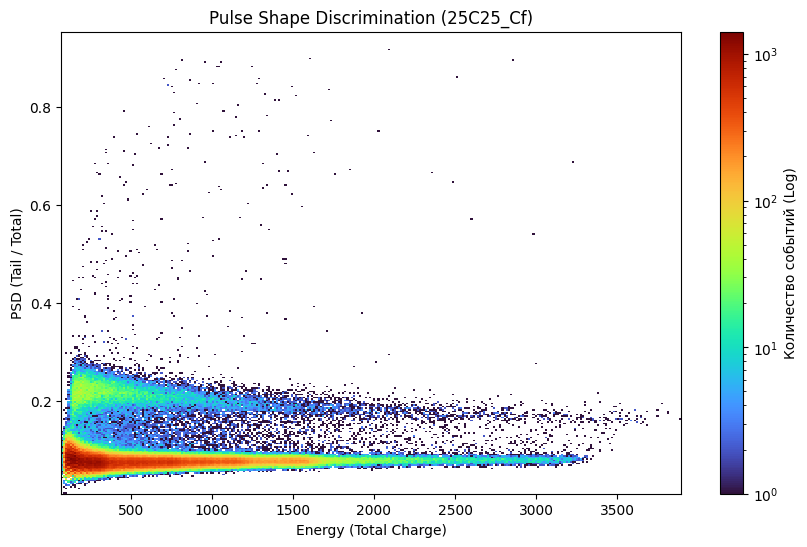

In [12]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

plt.figure(figsize=(10, 6))

plt.hist2d(
    x=processed_data['Energy'],
    y=processed_data['psd'],
    bins=(300, 300),
    cmap='turbo',
    norm=LogNorm()  # Проявит редкие события (нейтроны)
)

plt.colorbar(label='Количество событий (Log)')
plt.xlabel('Energy (Total Charge)')
plt.ylabel('PSD (Tail / Total)')
plt.title('Pulse Shape Discrimination (25C25_Cf)')

In [13]:
processed_data.write_parquet("datasets/25c25_proccesed.parquet")